<center><h1>Niu_Qiyu_HW7</h1></center>

**Name:** Qiyu Niu  
**GitHub Username:** QiyuNiu  
**USC ID:** 6184595941

## 1. Multi-class and Multi-Label Classification Using Support Vector Machines

### Imports

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.base import clone
from sklearn.cluster import KMeans
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    silhouette_score,
)
from sklearn.model_selection import GridSearchCV, StratifiedKFold, train_test_split
from sklearn.multiclass import OneVsRestClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import LinearSVC, SVC

from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as ImbPipeline

RANDOM_SEED = 552
DATA_DIR = Path("../data")
LABELS = ["Family", "Genus", "Species"]

### (a) Download the Anuran Calls (MFCCs) Data Set

In [2]:
frogs = pd.read_csv(DATA_DIR / "Frogs_MFCCs.csv")

print("Shape:", frogs.shape)
print("Missing values:", int(frogs.isna().sum().sum()))
display(frogs.head())

feature_columns = [column for column in frogs.columns if column.startswith("MFCCs")]
X = frogs[feature_columns]
y = frogs[LABELS]

for label in LABELS:
    print(f"{label} class counts:")
    display(y[label].value_counts().to_frame("Count"))

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    train_size=0.70,
    random_state=RANDOM_SEED,
)

print("Training set:", X_train.shape)
print("Test set:", X_test.shape)

Shape: (7195, 26)
Missing values: 0


,MFCCs_ 1,MFCCs_ 2,MFCCs_ 3,MFCCs_ 4,MFCCs_ 5,MFCCs_ 6,MFCCs_ 7,MFCCs_ 8,MFCCs_ 9,MFCCs_10,...,MFCCs_17,MFCCs_18,MFCCs_19,MFCCs_20,MFCCs_21,MFCCs_22,Family,Genus,Species,RecordID
0,1.0,0.152936,-0.105586,0.200722,0.317201,0.260764,0.100945,-0.150063,-0.171128,0.124676,...,-0.108351,-0.077623,-0.009568,0.057684,0.118680,0.014038,Leptodactylidae,Adenomera,AdenomeraAndre,1
1,1.0,0.171534,-0.098975,0.268425,0.338672,0.268353,0.060835,-0.222475,-0.207693,0.170883,...,-0.090974,-0.056510,-0.035303,0.020140,0.082263,0.029056,Leptodactylidae,Adenomera,AdenomeraAndre,1
2,1.0,0.152317,-0.082973,0.287128,0.276014,0.189867,0.008714,-0.242234,-0.219153,0.232538,...,-0.050691,-0.023590,-0.066722,-0.025083,0.099108,0.077162,Leptodactylidae,Adenomera,AdenomeraAndre,1
3,1.0,0.224392,0.118985,0.329432,0.372088,0.361005,0.015501,-0.194347,-0.098181,0.270375,...,-0.136009,-0.177037,-0.130498,-0.054766,-0.018691,0.023954,Leptodactylidae,Adenomera,AdenomeraAndre,1
4,1.0,0.087817,-0.068345,0.306967,0.330923,0.249144,0.006884,-0.265423,-0.172700,0.266434,...,-0.048885,-0.053074,-0.088550,-0.031346,0.108610,0.079244,Leptodactylidae,Adenomera,AdenomeraAndre,1


Family class counts:


,Count
Family,
Leptodactylidae,4420
Hylidae,2165
Dendrobatidae,542
Bufonidae,68


Genus class counts:


,Count
Genus,
Adenomera,4150
Hypsiboas,1593
Ameerega,542
Dendropsophus,310
Leptodactylus,270
Scinax,148
Osteocephalus,114
Rhinella,68


Species class counts:


,Count
Species,
AdenomeraHylaedactylus,3478
HypsiboasCordobae,1121
AdenomeraAndre,672
Ameeregatrivittata,542
HypsiboasCinerascens,472
HylaMinuta,310
LeptodactylusFuscus,270
ScinaxRuber,148
OsteocephalusOophagus,114


Training set: (5036, 22)
Test set: (2159, 22)


I use the 22 MFCC columns as predictors. `RecordID` identifies the recording,
so I do not use it as a predictor. The dataset has no missing values. I set the
random state to 552 so that the same 70:30 split can be reproduced.

### (b) Train a Classifier for Each Label

#### (i) Exact Match and Hamming Measures

Suppose there are $n$ observations and $L=3$ labels.

- **Exact match ratio** is the fraction of observations for which all three
  labels are predicted correctly. It is strict because one wrong label makes
  the whole observation incorrect.
- **Exact match loss** is one minus the exact match ratio.
- **Hamming loss** is the number of wrong individual labels divided by $nL$.
- **Hamming score** is $1-$ Hamming loss, so it is the fraction of individual
  labels that are correct.

A smaller exact match loss and Hamming loss are better. A larger exact match
ratio and Hamming score are better.

In [3]:
def multilabel_metrics(y_true, y_pred):
    true_array = np.asarray(y_true)
    pred_array = np.asarray(y_pred)
    wrong = true_array != pred_array

    exact_match = np.mean(np.all(~wrong, axis=1))
    hamming_loss = np.mean(wrong)

    return {
        "exact_match": exact_match,
        "exact_match_loss": 1 - exact_match,
        "hamming_loss": hamming_loss,
        "hamming_score": 1 - hamming_loss,
    }

#### (ii) Gaussian-Kernel SVMs

I train one model for each of the three labels. Each model uses one-versus-rest
classification. I standardize the predictors inside the pipeline and use
10-fold stratified cross-validation to choose $C$ and $\gamma$. For the RBF
kernel, $\gamma=1/(2\sigma^2)$, so I also report $\sigma$.

In [4]:
cv = StratifiedKFold(
    n_splits=10,
    shuffle=True,
    random_state=RANDOM_SEED,
)

rbf_pipeline = Pipeline([
    ("scale", StandardScaler()),
    ("svm", OneVsRestClassifier(SVC(kernel="rbf"))),
])

rbf_grid = {
    "svm__estimator__C": [0.1, 1, 10, 100],
    "svm__estimator__gamma": [0.1, 0.5, 1],
}

rbf_models = {}
rbf_predictions = pd.DataFrame(index=y_test.index)
rbf_rows = []

for label in LABELS:
    search = GridSearchCV(
        clone(rbf_pipeline),
        rbf_grid,
        cv=cv,
        scoring="accuracy",
        n_jobs=-1,
    )
    search.fit(X_train, y_train[label])

    prediction = search.predict(X_test)
    rbf_predictions[label] = prediction
    rbf_models[label] = search.best_estimator_

    best_c = search.best_params_["svm__estimator__C"]
    best_gamma = search.best_params_["svm__estimator__gamma"]
    best_sigma = np.sqrt(1 / (2 * best_gamma))

    rbf_rows.append({
        "Label": label,
        "Best C": best_c,
        "Best gamma": best_gamma,
        "Sigma": best_sigma,
        "CV accuracy": search.best_score_,
        "Test accuracy": accuracy_score(y_test[label], prediction),
        "Balanced accuracy": balanced_accuracy_score(y_test[label], prediction),
    })

rbf_results = pd.DataFrame(rbf_rows).set_index("Label")
display(rbf_results.round(4))

rbf_metrics = multilabel_metrics(y_test[LABELS], rbf_predictions[LABELS])
display(pd.DataFrame([rbf_metrics], index=["RBF SVM"]).round(4))

,Best C,Best gamma,Sigma,CV accuracy,Test accuracy,Balanced accuracy
Label,,,,,,
Family,10,0.1,2.2361,0.9903,0.9903,0.9710
Genus,10,0.1,2.2361,0.9895,0.9884,0.9579
Species,10,0.1,2.2361,0.9881,0.9875,0.9620


,exact_match,exact_match_loss,hamming_loss,hamming_score
RBF SVM,0.9852,0.0148,0.0113,0.9887


The test accuracies are 0.9903 for family, 0.9884 for genus, and 0.9875 for
species. The exact match is 0.9852 and the Hamming loss is 0.0113. Exact match
is lower than the individual accuracies because it requires all three labels
to be correct for the same observation.

#### (iii) L1-Penalized SVMs

An L1-penalized SVM uses a linear kernel. The L1 penalty can make some feature
coefficients exactly zero. I standardize the predictors and use 10-fold
cross-validation to select $C$ for each label.

In [5]:
l1_pipeline = Pipeline([
    ("scale", StandardScaler()),
    ("svm", OneVsRestClassifier(
        LinearSVC(
            penalty="l1",
            dual=False,
            max_iter=50000,
            random_state=RANDOM_SEED,
        )
    )),
])

l1_grid = {
    "svm__estimator__C": [0.01, 0.1, 1, 10, 100],
}

l1_models = {}
l1_predictions = pd.DataFrame(index=y_test.index)
l1_rows = []

for label in LABELS:
    search = GridSearchCV(
        clone(l1_pipeline),
        l1_grid,
        cv=cv,
        scoring="accuracy",
        n_jobs=-1,
    )
    search.fit(X_train, y_train[label])

    prediction = search.predict(X_test)
    l1_predictions[label] = prediction
    l1_models[label] = search.best_estimator_

    l1_rows.append({
        "Label": label,
        "Best C": search.best_params_["svm__estimator__C"],
        "CV accuracy": search.best_score_,
        "Test accuracy": accuracy_score(y_test[label], prediction),
        "Balanced accuracy": balanced_accuracy_score(y_test[label], prediction),
    })

l1_results = pd.DataFrame(l1_rows).set_index("Label")
display(l1_results.round(4))

l1_metrics = multilabel_metrics(y_test[LABELS], l1_predictions[LABELS])
display(pd.DataFrame([l1_metrics], index=["L1 SVM"]).round(4))

,Best C,CV accuracy,Test accuracy,Balanced accuracy
Label,,,,
Family,1,0.9378,0.9333,0.6928
Genus,10,0.9547,0.9523,0.8314
Species,1,0.9581,0.9565,0.8881


,exact_match,exact_match_loss,hamming_loss,hamming_score
L1 SVM,0.9176,0.0824,0.0526,0.9474


The L1 SVM has an exact match of 0.9176 and a Hamming loss of 0.0526. These
results are worse than the RBF SVM. A linear model is simpler, but it cannot
represent the nonlinear class boundaries as well as the RBF kernel.

#### (iv) L1-Penalized SVMs with SMOTE

The label counts are uneven, especially for the smaller frog classes. I put
SMOTE inside the cross-validation pipeline so that synthetic observations are
created only from each training fold. This avoids using validation-fold
information while oversampling.

In [6]:
smote_pipeline = ImbPipeline([
    ("scale", StandardScaler()),
    ("smote", SMOTE(random_state=RANDOM_SEED)),
    ("svm", OneVsRestClassifier(
        LinearSVC(
            penalty="l1",
            dual=False,
            max_iter=50000,
            random_state=RANDOM_SEED,
        )
    )),
])

smote_models = {}
smote_predictions = pd.DataFrame(index=y_test.index)
smote_rows = []

for label in LABELS:
    search = GridSearchCV(
        clone(smote_pipeline),
        l1_grid,
        cv=cv,
        scoring="accuracy",
        n_jobs=2,
    )
    search.fit(X_train, y_train[label])

    prediction = search.predict(X_test)
    smote_predictions[label] = prediction
    smote_models[label] = search.best_estimator_

    smote_rows.append({
        "Label": label,
        "Best C": search.best_params_["svm__estimator__C"],
        "CV accuracy": search.best_score_,
        "Test accuracy": accuracy_score(y_test[label], prediction),
        "Balanced accuracy": balanced_accuracy_score(y_test[label], prediction),
    })

smote_results = pd.DataFrame(smote_rows).set_index("Label")
display(smote_results.round(4))

smote_metrics = multilabel_metrics(y_test[LABELS], smote_predictions[LABELS])

comparison = pd.DataFrame(
    [rbf_metrics, l1_metrics, smote_metrics],
    index=["RBF SVM", "L1 SVM", "L1 SVM + SMOTE"],
)
comparison["mean_label_accuracy"] = [
    rbf_results["Test accuracy"].mean(),
    l1_results["Test accuracy"].mean(),
    smote_results["Test accuracy"].mean(),
]
comparison["mean_balanced_accuracy"] = [
    rbf_results["Balanced accuracy"].mean(),
    l1_results["Balanced accuracy"].mean(),
    smote_results["Balanced accuracy"].mean(),
]
display(comparison.round(4))

,Best C,CV accuracy,Test accuracy,Balanced accuracy
Label,,,,
Family,100.0,0.9228,0.9134,0.9197
Genus,1.0,0.9172,0.9111,0.8912
Species,0.1,0.9551,0.9509,0.9035


,exact_match,exact_match_loss,hamming_loss,hamming_score,mean_label_accuracy,mean_balanced_accuracy
RBF SVM,0.9852,0.0148,0.0113,0.9887,0.9887,0.9637
L1 SVM,0.9176,0.0824,0.0526,0.9474,0.9474,0.8041
L1 SVM + SMOTE,0.8620,0.1380,0.0749,0.9251,0.9251,0.9048


The RBF SVM gives the best result, with exact match 0.9852 and Hamming loss
0.0113. The L1 SVM has mean balanced accuracy 0.8041. After SMOTE, it increases
to 0.9048, so the small classes are classified more evenly. At the same time,
mean label accuracy decreases from 0.9474 to 0.9251 and exact match decreases
to 0.8620. In this dataset, SMOTE improves balance but does not improve the
overall prediction result.

## 2. K-Means Clustering on a Multi-Class and Multi-Label Data Set

### (a) Choose $k$ Automatically

I use the silhouette score to select $k$. A silhouette score is not defined
for one cluster, so the automatic comparison starts at $k=2$ and continues to
$k=50$. Each Monte Carlo run uses a different K-means initialization. I use a
sample of 500 observations for the silhouette calculation so that all 49
candidate values can be compared in a reasonable time.

Selected k in the first run: 4


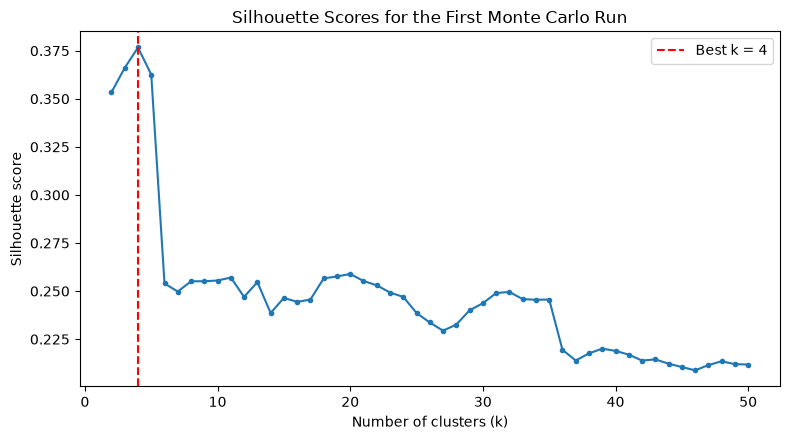

In [7]:
X_all = X.to_numpy()
y_all = y.reset_index(drop=True)


def choose_k(seed):
    scores = []
    best_score = -np.inf
    best_k = None
    best_clusters = None

    for k in range(2, 51):
        model = KMeans(
            n_clusters=k,
            n_init=1,
            max_iter=100,
            random_state=seed,
        )
        clusters = model.fit_predict(X_all)
        score = silhouette_score(
            X_all,
            clusters,
            sample_size=500,
            random_state=seed,
        )
        scores.append(score)

        if score > best_score:
            best_score = score
            best_k = k
            best_clusters = clusters.copy()

    return best_k, best_clusters, scores


first_k, first_clusters, first_scores = choose_k(RANDOM_SEED)
print("Selected k in the first run:", first_k)

plt.figure(figsize=(8, 4.5))
plt.plot(range(2, 51), first_scores, marker="o", markersize=3)
plt.axvline(first_k, color="red", linestyle="--", label=f"Best k = {first_k}")
plt.xlabel("Number of clusters (k)")
plt.ylabel("Silhouette score")
plt.title("Silhouette Scores for the First Monte Carlo Run")
plt.legend()
plt.tight_layout()
plt.show()

### (b) Find the Majority Family, Genus, and Species

In [8]:
def assign_cluster_majorities(cluster_ids):
    assigned = np.empty((len(cluster_ids), len(LABELS)), dtype=object)
    majority_rows = []

    for cluster in np.unique(cluster_ids):
        rows = cluster_ids == cluster
        row = {"Cluster": cluster, "Size": int(rows.sum())}

        for column_index, label in enumerate(LABELS):
            majority = y_all.loc[rows, label].mode().iloc[0]
            row[label] = majority
            assigned[rows, column_index] = majority

        majority_rows.append(row)

    majority_table = pd.DataFrame(majority_rows).set_index("Cluster")
    return assigned, majority_table


first_assigned, first_majorities = assign_cluster_majorities(first_clusters)
display(first_majorities)

,Size,Family,Genus,Species
Cluster,,,,
0,723,Leptodactylidae,Adenomera,AdenomeraAndre
1,3584,Leptodactylidae,Adenomera,AdenomeraHylaedactylus
2,2221,Hylidae,Hypsiboas,HypsiboasCordobae
3,667,Hylidae,Hypsiboas,HypsiboasCinerascens


The table gives one majority triplet to each cluster. Every observation in a
cluster receives that cluster's family, genus, and species as its predicted
labels.

### (c) Hamming Distance, Hamming Score, and Hamming Loss

For each observation, the Hamming distance is the number of incorrect labels
among the three labels. The average Hamming distance is therefore between 0
and 3. Hamming loss divides that value by 3, and Hamming score is one minus
Hamming loss.

,k,Hamming distance,Hamming loss,Hamming score
Run,,,,
1,4,0.700208,0.233403,0.766597
2,4,0.667269,0.222423,0.777577
3,4,0.700069,0.233356,0.766644
4,6,0.580959,0.193653,0.806347
5,3,0.715914,0.238638,0.761362
6,3,0.890341,0.296780,0.703220
7,4,0.557748,0.185916,0.814084
8,6,0.579291,0.193097,0.806903
9,2,0.895622,0.298541,0.701459


,Hamming distance,Hamming loss,Hamming score
mean,0.7350,0.2450,0.7550
std,0.1265,0.0422,0.0422


Selected k frequencies:


,Count
k,
2,7
3,16
4,20
6,5
7,1
8,1


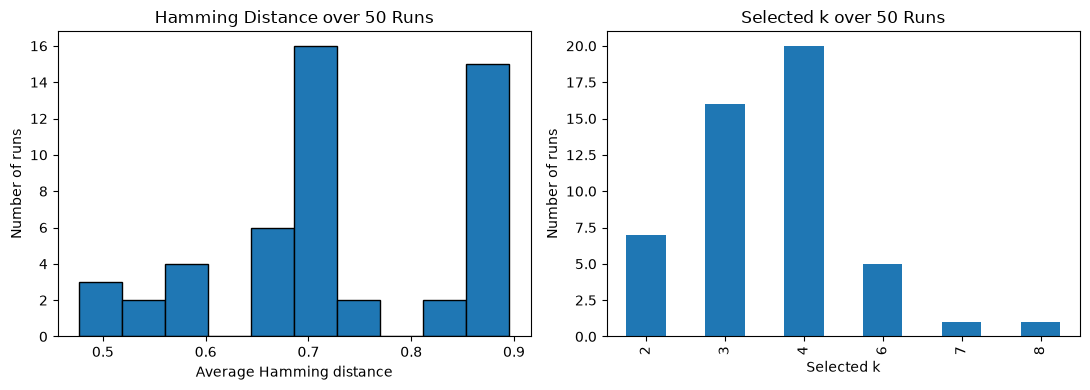

In [9]:
def clustering_metrics(assigned_labels):
    wrong = y_all[LABELS].to_numpy() != assigned_labels
    average_distance = wrong.sum(axis=1).mean()
    loss = wrong.mean()

    return {
        "Hamming distance": average_distance,
        "Hamming loss": loss,
        "Hamming score": 1 - loss,
    }


monte_carlo_rows = []

first_metrics = clustering_metrics(first_assigned)
monte_carlo_rows.append({"Run": 1, "k": first_k, **first_metrics})

for run in range(1, 50):
    selected_k, clusters, _ = choose_k(RANDOM_SEED + run)
    assigned, _ = assign_cluster_majorities(clusters)
    metrics = clustering_metrics(assigned)
    monte_carlo_rows.append({"Run": run + 1, "k": selected_k, **metrics})

monte_carlo = pd.DataFrame(monte_carlo_rows).set_index("Run")
display(monte_carlo)

summary = monte_carlo[[
    "Hamming distance", "Hamming loss", "Hamming score"
]].agg(["mean", "std"])
display(summary.round(4))

print("Selected k frequencies:")
display(monte_carlo["k"].value_counts().sort_index().to_frame("Count"))

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].hist(monte_carlo["Hamming distance"], bins=10, edgecolor="black")
axes[0].set_xlabel("Average Hamming distance")
axes[0].set_ylabel("Number of runs")
axes[0].set_title("Hamming Distance over 50 Runs")

monte_carlo["k"].value_counts().sort_index().plot.bar(ax=axes[1])
axes[1].set_xlabel("Selected k")
axes[1].set_ylabel("Number of runs")
axes[1].set_title("Selected k over 50 Runs")

plt.tight_layout()
plt.show()

Over the 50 runs, the mean Hamming distance is 0.7350 with a standard deviation
of 0.1265. The mean Hamming loss is 0.2450 and the mean Hamming score is 0.7550.
The most common choice is $k=4$ (20 runs), followed by $k=3$ (16 runs). The
variation comes from the random K-means starts and the silhouette sample.

## 3. ISLR 12.6.2

The dissimilarities are

$$
D=\begin{bmatrix}
0 & 0.3 & 0.4 & 0.7\\
0.3 & 0 & 0.5 & 0.8\\
0.4 & 0.5 & 0 & 0.45\\
0.7 & 0.8 & 0.45 & 0
\end{bmatrix}.
$$

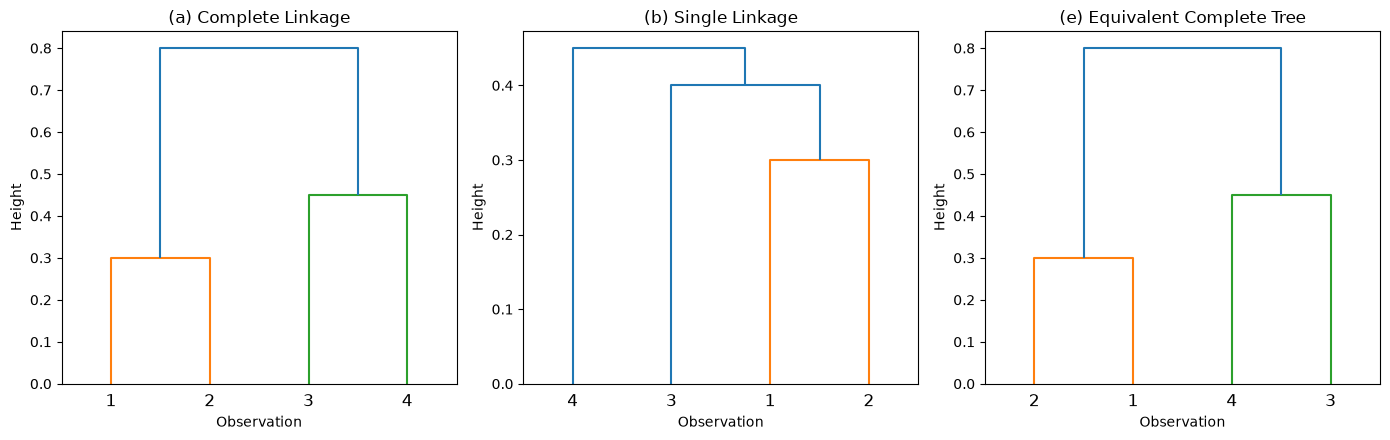

In [10]:
from scipy.cluster.hierarchy import dendrogram, linkage
from scipy.spatial.distance import squareform

dissimilarities = np.array([
    [0.00, 0.30, 0.40, 0.70],
    [0.30, 0.00, 0.50, 0.80],
    [0.40, 0.50, 0.00, 0.45],
    [0.70, 0.80, 0.45, 0.00],
])

condensed = squareform(dissimilarities)
complete_linkage = linkage(condensed, method="complete")
single_linkage = linkage(condensed, method="single")

# Same complete-linkage tree, but the leaves inside each pair are swapped.
equivalent_complete = np.array([
    [1, 0, 0.30, 2],
    [3, 2, 0.45, 2],
    [4, 5, 0.80, 4],
])

fig, axes = plt.subplots(1, 3, figsize=(14, 4.5))
dendrogram(complete_linkage, labels=["1", "2", "3", "4"], ax=axes[0])
axes[0].set_title("(a) Complete Linkage")

dendrogram(single_linkage, labels=["1", "2", "3", "4"], ax=axes[1])
axes[1].set_title("(b) Single Linkage")

dendrogram(equivalent_complete, labels=["1", "2", "3", "4"], ax=axes[2])
axes[2].set_title("(e) Equivalent Complete Tree")

for axis in axes:
    axis.set_xlabel("Observation")
    axis.set_ylabel("Height")

plt.tight_layout()
plt.show()

**(a) Complete linkage:** Observations 1 and 2 merge first at height 0.30.
Observations 3 and 4 merge at height 0.45. The distance between the two
clusters is the largest cross-cluster dissimilarity, which is 0.80, so the
two pairs merge at height 0.80.

**(b) Single linkage:** Observations 1 and 2 merge at height 0.30. Observation
3 then joins them at height 0.40 because the smallest distance from 3 to the
cluster $\{1,2\}$ is 0.40. Observation 4 joins last at height 0.45 because its
smallest distance to $\{1,2,3\}$ is the distance to observation 3.

**(c)** Cutting the complete-linkage dendrogram into two clusters gives
$\{1,2\}$ and $\{3,4\}$.

**(d)** Cutting the single-linkage dendrogram into two clusters gives
$\{1,2,3\}$ and $\{4\}$.

**(e)** The third plot is equivalent to the first plot. The leaves inside both
pairs are reversed, but the same observations merge at the same heights.